
# MiniGPT - Transformer Language Model from Scratch

Implementation and training of a decoder-only Transformer using PyTorch and the TinyStories dataset.

The project covers data preparation, BPE tokenization, causal multi-head attention, Transformer architecture, training, evaluation and autoregressive text generation.

The model is trained from scratch without pretrained weights or PyTorch's built-in Transformer modules.

**Training:** 1.25 million stories, 20,000 optimization steps


## 1. Data Preparation

In [1]:
!pip -q install datasets tokenizers

In [2]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from itertools import islice
from pathlib import Path
from datasets import load_dataset
from tokenizers import ByteLevelBPETokenizer

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
use_amp = device == "cuda"

save_dir = Path("/content/minigpt")
save_dir.mkdir(parents=True, exist_ok=True)

num_train_stories = 1250000
num_val_stories = 2000
batch_size = 16
block_size = 256

print("Device:", device)

Device: cuda


In [3]:
import logging
logging.getLogger("huggingface_hub.utils._http").setLevel(logging.ERROR)

train_stream = load_dataset("roneneldan/TinyStories", split="train", streaming=True)
val_stream = load_dataset("roneneldan/TinyStories", split="validation", streaming=True)

train_texts = [row["text"] for row in islice(train_stream, num_train_stories)]
val_texts = [row["text"] for row in islice(val_stream, num_val_stories)]

tokenizer = ByteLevelBPETokenizer()
tokenizer.train_from_iterator(
    train_texts,
    vocab_size=4096,
    min_frequency=2,
    special_tokens=["<|endoftext|>"]
)
tokenizer.save(str(save_dir / "tokenizer.json"))

vocab_size = tokenizer.get_vocab_size()
eos_id = tokenizer.token_to_id("<|endoftext|>")

def encode_stories(texts):
    ids = np.fromiter(
        (token_id for text in texts
         for token_id in tokenizer.encode(text).ids + [eos_id]),
        dtype=np.int32
    )
    return torch.from_numpy(ids)

train_tokens = encode_stories(train_texts)
val_tokens = encode_stories(val_texts)
del train_texts, val_texts

print(f"Train tokens: {len(train_tokens):,} | Validation tokens: {len(val_tokens):,}")
print("Vocabulary size:", vocab_size)

Train tokens: 286,785,619 | Validation tokens: 399,011
Vocabulary size: 4096


In [4]:
def get_batch(split="train"):
    data = train_tokens if split == "train" else val_tokens
    starts = torch.randint(0, len(data) - block_size, (batch_size,))
    offsets = torch.arange(block_size)
    indices = starts[:, None] + offsets[None, :]

    x = data[indices].to(device=device, dtype=torch.long)
    y = data[indices + 1].to(device=device, dtype=torch.long)
    return x, y

## 2. Transformer architecture

In [5]:
class CausalSelfAttention(nn.Module):
    def __init__(self, n_embd, n_head, block_size):
        super().__init__()
        assert n_embd % n_head == 0
        self.n_head = n_head
        self.head_dim = n_embd // n_head
        self.qkv = nn.Linear(n_embd, 3 * n_embd)
        self.proj = nn.Linear(n_embd, n_embd)

        mask = torch.tril(torch.ones(block_size, block_size, dtype=torch.bool))
        self.register_buffer("causal_mask", mask.view(1, 1, block_size, block_size))

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=-1)
        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.head_dim).transpose(1, 2)

        scores = (q @ k.transpose(-2, -1)) * (self.head_dim ** -0.5)
        scores = scores.masked_fill(
            ~self.causal_mask[:, :, :T, :T], torch.finfo(scores.dtype).min
        )
        weights = F.softmax(scores, dim=-1)
        out = weights @ v
        out = out.transpose(1, 2).contiguous().view(B, T, C)
        return self.proj(out)


class FeedForward(nn.Module):
    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.GELU(),
            nn.Linear(4 * n_embd, n_embd),
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    def __init__(self, n_embd, n_head, block_size):
        super().__init__()
        self.ln1 = nn.LayerNorm(n_embd)
        self.attn = CausalSelfAttention(n_embd, n_head, block_size)
        self.ln2 = nn.LayerNorm(n_embd)
        self.ff = FeedForward(n_embd)

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.ff(self.ln2(x))
        return x


class MiniGPT(nn.Module):
    def __init__(self, vocab_size, block_size, n_embd=128, n_head=4, n_layer=4):
        super().__init__()
        self.block_size = block_size
        self.token_embedding = nn.Embedding(vocab_size, n_embd)
        self.position_embedding = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[
            TransformerBlock(n_embd, n_head, block_size)
            for _ in range(n_layer)
        ])
        self.ln_final = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size, bias=False)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        if T > self.block_size:
            raise ValueError("Input exceeds context length")

        positions = torch.arange(T, device=idx.device)
        x = self.token_embedding(idx) + self.position_embedding(positions)
        x = self.ln_final(self.blocks(x))
        logits = self.lm_head(x)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)), targets.reshape(-1)
            )
        return logits, loss

## 3. Training

In [6]:
model_config = {
    "vocab_size": vocab_size,
    "block_size": block_size,
    "n_embd": 384,
    "n_head": 8,
    "n_layer": 6,
}
model = MiniGPT(**model_config).to(device)

max_steps = 20_000
warmup_steps = 200
max_lr = 3e-4
min_lr = 3e-5
eval_interval = 500
eval_batches = 20

optimizer = torch.optim.AdamW(model.parameters(), lr=max_lr, weight_decay=0.1)
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

fixed_eval = {
    split: [get_batch(split) for _ in range(eval_batches)]
    for split in ("train", "val")
}


def get_lr(step):
    if step < warmup_steps:
        return max_lr * (step + 1) / warmup_steps
    progress = min(1.0, (step - warmup_steps) / max(1, max_steps - warmup_steps - 1))
    return min_lr + 0.5 * (max_lr - min_lr) * (1 + math.cos(math.pi * progress))


@torch.no_grad()
def estimate_loss():
    model.eval()
    metrics = {}
    for split, batches in fixed_eval.items():
        losses = []
        for x, y in batches:
            with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
                _, loss = model(x, y)
            losses.append(loss.float().item())
        metrics[split] = sum(losses) / len(losses)
    model.train()
    return metrics


print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")

Model parameters: 13,891,584


In [7]:
history = []
best_val_loss = float("inf")

for step in range(max_steps + 1):
    if step > 0:
        model.train()
        lr = get_lr(step - 1)
        for group in optimizer.param_groups:
            group["lr"] = lr

        x, y = get_batch("train")
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
            _, loss = model(x, y)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

    if step % eval_interval == 0 or step == max_steps:
        metrics = estimate_loss()
        history.append({"step": step, "train_loss": metrics["train"], "val_loss": metrics["val"]})

        print(f"Step {step:5d} | Train {metrics['train']:.4f} | Val {metrics['val']:.4f}")
        if metrics["val"] < best_val_loss:
            best_val_loss = metrics["val"]
            torch.save({
                "model": model.state_dict(),
                "model_config": model_config,
                "step": step,
                "val_loss": best_val_loss,
            }, save_dir / "best.pt")

print("Best validation loss:", round(best_val_loss, 4))

Step     0 | Train 8.5059 | Val 8.5053
Step   500 | Train 3.8788 | Val 3.8914
Step  1000 | Train 3.3136 | Val 3.3301
Step  1500 | Train 3.0022 | Val 3.0316
Step  2000 | Train 2.8138 | Val 2.8431
Step  2500 | Train 2.6792 | Val 2.7064
Step  3000 | Train 2.5724 | Val 2.5972
Step  3500 | Train 2.4827 | Val 2.5055
Step  4000 | Train 2.4033 | Val 2.4324
Step  4500 | Train 2.3412 | Val 2.3706
Step  5000 | Train 2.2798 | Val 2.3116
Step  5500 | Train 2.2338 | Val 2.2670
Step  6000 | Train 2.1884 | Val 2.2225
Step  6500 | Train 2.1610 | Val 2.1890
Step  7000 | Train 2.1300 | Val 2.1579
Step  7500 | Train 2.1038 | Val 2.1306
Step  8000 | Train 2.0799 | Val 2.1073
Step  8500 | Train 2.0562 | Val 2.0838
Step  9000 | Train 2.0377 | Val 2.0686
Step  9500 | Train 2.0156 | Val 2.0453
Step 10000 | Train 1.9995 | Val 2.0288
Step 10500 | Train 1.9825 | Val 2.0125
Step 11000 | Train 1.9682 | Val 1.9990
Step 11500 | Train 1.9516 | Val 1.9792
Step 12000 | Train 1.9382 | Val 1.9680
Step 12500 | Train 1.9238

## 4. Evaluation

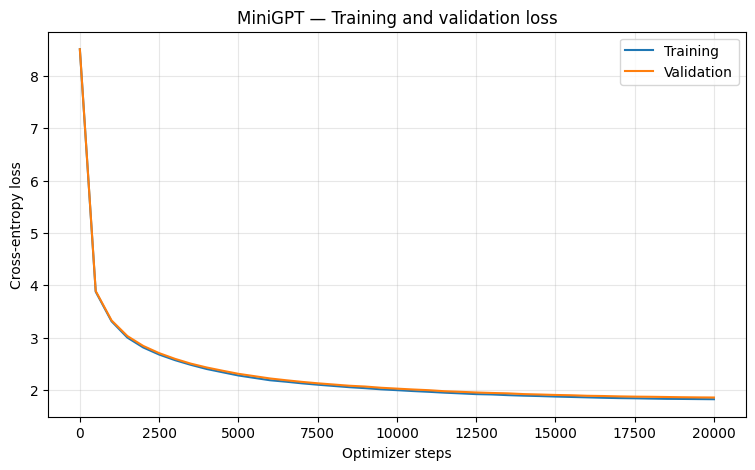

Best checkpoint step: 20000
Validation loss: 1.8595
Perplexity: 6.42


In [8]:
steps = [record["step"] for record in history]
plt.figure(figsize=(9, 5))
plt.plot(steps, [record["train_loss"] for record in history], label="Training")
plt.plot(steps, [record["val_loss"] for record in history], label="Validation")
plt.xlabel("Optimizer steps")
plt.ylabel("Cross-entropy loss")
plt.title("MiniGPT — Training and validation loss")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

checkpoint = torch.load(save_dir / "best.pt", map_location=device, weights_only=True)
model.load_state_dict(checkpoint["model"])
model.eval()

print("Best checkpoint step:", checkpoint["step"])
print("Validation loss:", round(checkpoint["val_loss"], 4))
print("Perplexity:", round(math.exp(checkpoint["val_loss"]), 2))

## 5. Text generation

In [11]:
@torch.inference_mode()
def generate(model, tokenizer, prompt, max_new_tokens, temperature, top_k):
    model.eval()
    if temperature < 0 or (top_k is not None and top_k < 1):
        raise ValueError("temperature must be >= 0 and top_k must be >= 1 or None")

    prompt_ids = tokenizer.encode(prompt).ids
    if not prompt_ids:
        raise ValueError("Please provide a non-empty prompt")
    idx = torch.tensor([prompt_ids], dtype=torch.long, device=device)
    eos_id = tokenizer.token_to_id("<|endoftext|>")

    for _ in range(max_new_tokens):
        logits, _ = model(idx[:, -model.block_size:])
        logits = logits[:, -1, :].float()

        if temperature == 0:
            next_token = torch.argmax(logits, dim=-1, keepdim=True)
        else:
            logits = logits / temperature
            if top_k is not None:
                k = min(top_k, logits.size(-1))
                cutoff = torch.topk(logits, k).values[:, -1:]
                logits = logits.masked_fill(logits < cutoff, float("-inf"))
            probabilities = F.softmax(logits, dim=-1)
            next_token = torch.multinomial(probabilities, num_samples=1)

        if eos_id is not None and next_token.item() == eos_id:
            break
        idx = torch.cat([idx, next_token], dim=1)

    return tokenizer.decode(idx[0].tolist(), skip_special_tokens=True)


prompt = "Once upon a time, there was a little dragon"
story = generate(model, tokenizer, prompt, max_new_tokens=150, temperature=0.6, top_k=20)
print(story)

Once upon a time, there was a little dragon. The dragon was very happy and liked to fly around the house. One day, the dragon saw a little boy who was lost. The boy wanted to help the little boy, so he flew to the boy. The little boy was very happy and said, "Thank you, little dragon! You are very kind." The dragon knew that he could help the little boy find his way home. From that day on, the dragon and the little boy became good friends and always helped each other whenever they needed it.



## Reference

Dataset: [TinyStories](https://huggingface.co/datasets/roneneldan/TinyStories) — Eldan & Li (2023).
